In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORT_DIR = ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [26]:
saved = joblib.load(
    ROOT / "models" / "lightgbm_model.joblib"
)

model = saved["model"]
preprocessor = saved["preprocessor"]
features = saved["features"]

print("Model:", type(model).__name__)
print("Original features:", len(features))

Model: LGBMClassifier
Original features: 27


In [27]:
DATA_PATH = (
    ROOT / "data" / "processed" /
    "modeling_features.parquet"
)

con = duckdb.connect()

df = con.execute(
    "SELECT * FROM read_parquet(?)",
    [str(DATA_PATH)]
).df()

X = df[features].copy()
y = df["TARGET"].astype(int)

numeric_cols = X.select_dtypes(
    include=np.number
).columns

X[numeric_cols] = X[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

assert len(X_val) == 61502
assert len(X_test) == 61503

In [28]:
X_val_processed = preprocessor.transform(X_val)

probabilities = model.predict_proba(
    X_val_processed
)[:, 1]

actual = y_val.to_numpy()

print("ROC-AUC:", round(roc_auc_score(actual, probabilities), 4))
print(
    "Average Precision:",
    round(average_precision_score(actual, probabilities), 4)
)
print("Total positive cases:", int(actual.sum()))

/Users/preeyapat/miniconda3/envs/homecredit/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC-AUC: 0.7541
Average Precision: 0.2373
Total positive cases: 4965


In [29]:
def evaluate_decisions(y_true, flagged):
    y_true = np.asarray(y_true).astype(int)
    flagged = np.asarray(flagged).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, flagged,
        labels=[0, 1]
    ).ravel()

    n = len(y_true)
    reviewed = int(flagged.sum())

    return {
        "Applicants": n,
        "Flagged": reviewed,
        "Review_Rate": reviewed / n,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": precision_score(
            y_true, flagged, zero_division=0
        ),
        "Recall": recall_score(
            y_true, flagged, zero_division=0
        ),
        "FPR": fp / (fp + tn) if fp + tn else np.nan
    }

In [30]:
thresholds = np.round(
    np.arange(0.02, 0.51, 0.01),
    2
)

threshold_results = []

for threshold in thresholds:
    flagged = probabilities >= threshold

    metrics = evaluate_decisions(actual, flagged)

    threshold_results.append({
        "Threshold": threshold,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df[
        threshold_df["Threshold"].isin(
            [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]
        )
    ].round(4)
)

,Threshold,Applicants,Flagged,Review_Rate,TP,FP,FN,TN,Precision,Recall,FPR
3,0.05,61502,32797,0.5333,4136,28661,829,27876,0.1261,0.8330,0.5069
8,0.10,61502,15745,0.2560,2956,12789,2009,43748,0.1877,0.5954,0.2262
13,0.15,61502,8590,0.1397,2082,6508,2883,50029,0.2424,0.4193,0.1151
18,0.20,61502,4982,0.0810,1435,3547,3530,52990,0.2880,0.2890,0.0627
28,0.30,61502,1664,0.0271,624,1040,4341,55497,0.3750,0.1257,0.0184
48,0.50,61502,156,0.0025,86,70,4879,56467,0.5513,0.0173,0.0012


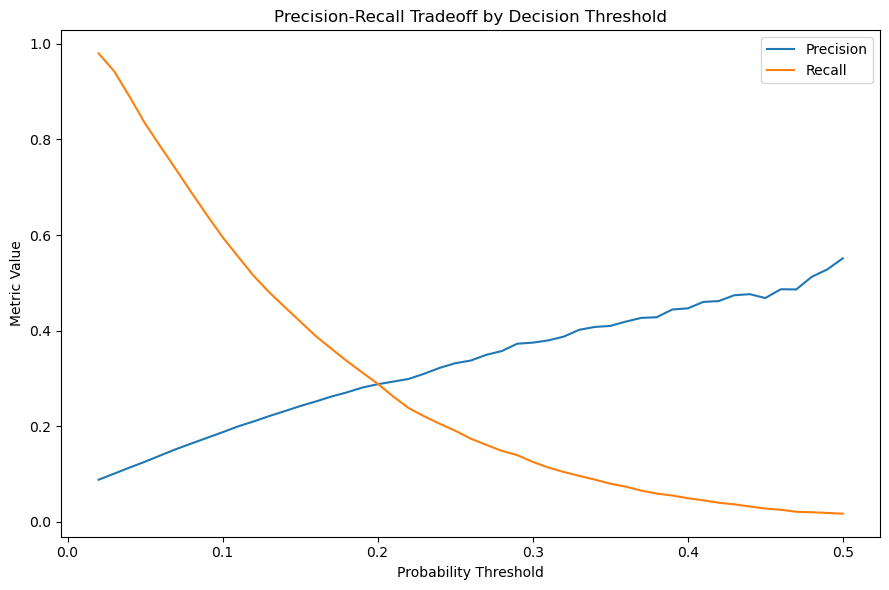

In [31]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Metric Value")
ax.set_title("Precision-Recall Tradeoff by Decision Threshold")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day10_threshold_tradeoff.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

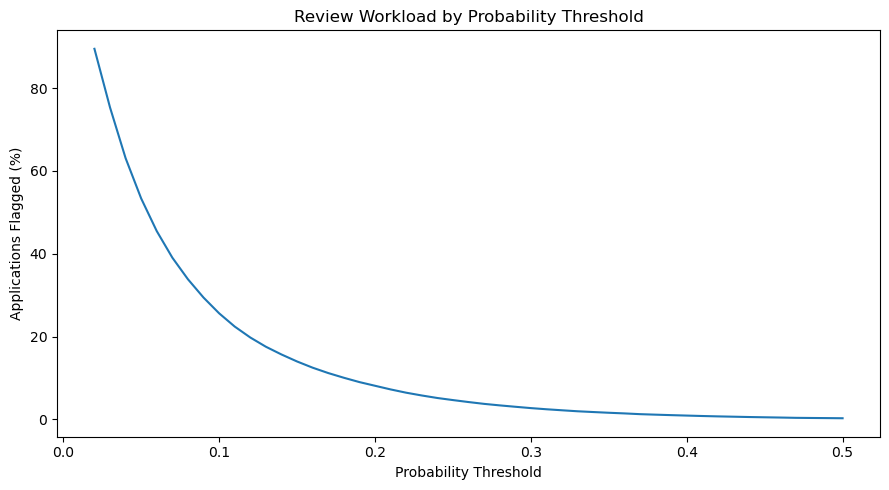

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Review_Rate"] * 100
)

ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Applications Flagged (%)")
ax.set_title("Review Workload by Probability Threshold")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day10_review_workload.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [33]:
def flag_top_fraction(probabilities, fraction):
    probabilities = np.asarray(probabilities)

    n = len(probabilities)
    k = int(np.ceil(n * fraction))

    selected = np.argsort(
        -probabilities,
        kind="stable"
    )[:k]

    flagged = np.zeros(n, dtype=int)
    flagged[selected] = 1

    return flagged

In [34]:
capacities = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]

capacity_results = []

for capacity in capacities:
    flagged = flag_top_fraction(
        probabilities, capacity
    )

    capacity_results.append({
        "Requested_Capacity": capacity,
        **evaluate_decisions(actual, flagged)
    })

capacity_df = pd.DataFrame(capacity_results)

display(
    capacity_df[
        [
            "Requested_Capacity",
            "Flagged",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall"
        ]
    ].round(4)
)

,Requested_Capacity,Flagged,TP,FP,FN,Precision,Recall
0,0.05,3076,995,2081,3970,0.3235,0.2004
1,0.10,6151,1669,4482,3296,0.2713,0.3362
2,0.15,9226,2176,7050,2789,0.2359,0.4383
3,0.20,12301,2572,9729,2393,0.2091,0.5180
4,0.25,15376,2909,12467,2056,0.1892,0.5859
5,0.30,18451,3215,15236,1750,0.1742,0.6475
6,0.40,24601,3697,20904,1268,0.1503,0.7446
7,0.50,30751,4037,26714,928,0.1313,0.8131


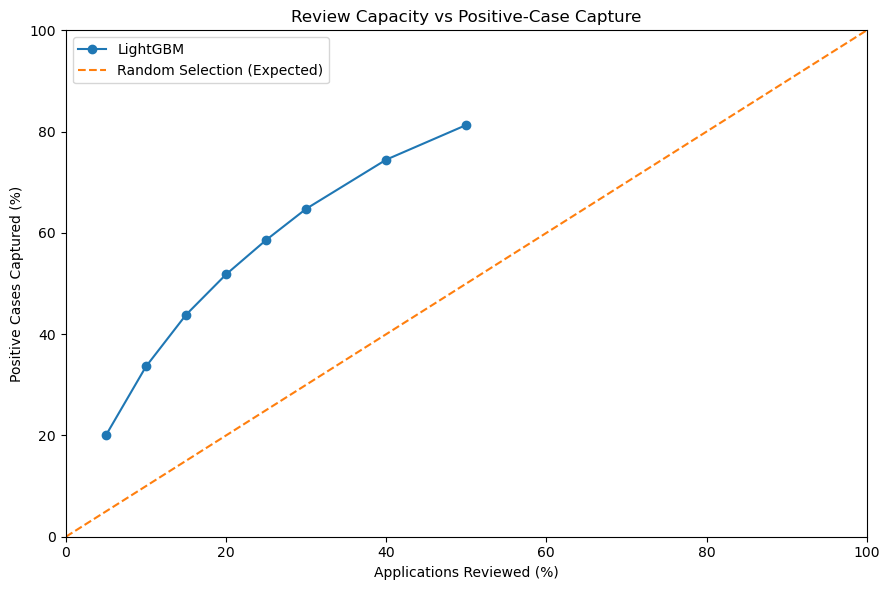

In [35]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    capacity_df["Review_Rate"] * 100,
    capacity_df["Recall"] * 100,
    marker="o",
    label="LightGBM"
)

ax.plot(
    [0, 100],
    [0, 100],
    "--",
    label="Random Selection (Expected)"
)

ax.set_xlabel("Applications Reviewed (%)")
ax.set_ylabel("Positive Cases Captured (%)")
ax.set_title("Review Capacity vs Positive-Case Capture")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day10_capacity_tradeoff.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [36]:
REVIEW_COST = 25

MISSED_CASE_COST = 500

print("Review cost per flagged application:", REVIEW_COST)
print("Missed-case cost:", MISSED_CASE_COST)

Review cost per flagged application: 25
Missed-case cost: 500


In [37]:
def calculate_cost(
    results,
    review_cost,
    missed_case_cost
):
    return (
        results["Flagged"] * review_cost
        + results["FN"] * missed_case_cost
    )


threshold_df["Modeled_Cost"] = calculate_cost(
    threshold_df,
    REVIEW_COST,
    MISSED_CASE_COST
)

threshold_df["Cost_Per_Application"] = (
    threshold_df["Modeled_Cost"]
    / threshold_df["Applicants"]
)

display(
    threshold_df[
        [
            "Threshold",
            "Flagged",
            "TP",
            "FN",
            "Modeled_Cost",
            "Cost_Per_Application"
        ]
    ].round(2).head(15)
)

,Threshold,Flagged,TP,FN,Modeled_Cost,Cost_Per_Application
0,0.02,55039,4865,100,1425975,23.19
1,0.03,46329,4680,285,1300725,21.15
2,0.04,38788,4415,550,1244700,20.24
3,0.05,32797,4136,829,1234425,20.07
4,0.06,27951,3895,1070,1233775,20.06
5,0.07,24007,3658,1307,1253675,20.38
6,0.08,20801,3417,1548,1294025,21.04
7,0.09,18081,3183,1782,1343025,21.84
8,0.10,15745,2956,2009,1398125,22.73
9,0.11,13776,2754,2211,1449900,23.57


In [38]:
best_row = threshold_df.loc[
    threshold_df["Modeled_Cost"].idxmin()
]

display(
    best_row[
        [
            "Threshold",
            "Flagged",
            "Review_Rate",
            "Precision",
            "Recall",
            "FN",
            "Modeled_Cost"
        ]
    ]
)

Threshold       6.000000e-02
Flagged         2.795100e+04
Review_Rate     4.544730e-01
Precision       1.393510e-01
Recall          7.844914e-01
FN              1.070000e+03
Modeled_Cost    1.233775e+06
Name: 4, dtype: float64

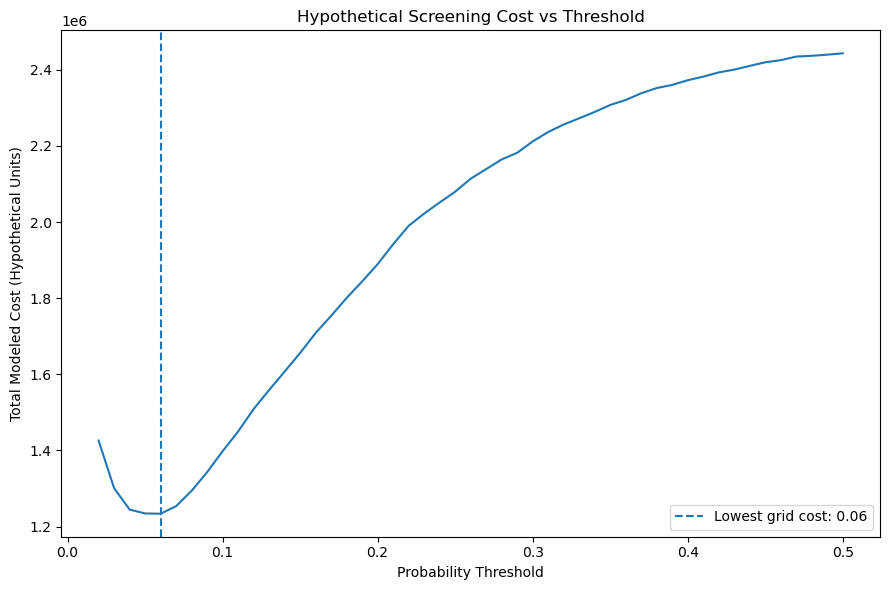

In [39]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    threshold_df["Threshold"],
    threshold_df["Modeled_Cost"]
)

ax.axvline(
    best_row["Threshold"],
    linestyle="--",
    label=f"Lowest grid cost: {best_row['Threshold']:.2f}"
)

ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Total Modeled Cost (Hypothetical Units)")
ax.set_title("Hypothetical Screening Cost vs Threshold")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day10_cost_by_threshold.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [40]:
cost_scenarios = {
    "Low Missed-Case Cost": {
        "review_cost": 25,
        "missed_cost": 125
    },
    "Moderate Missed-Case Cost": {
        "review_cost": 25,
        "missed_cost": 250
    },
    "High Missed-Case Cost": {
        "review_cost": 25,
        "missed_cost": 500
    },
    "Very High Missed-Case Cost": {
        "review_cost": 25,
        "missed_cost": 1000
    }
}

In [41]:
scenario_results = []

for scenario_name, costs in cost_scenarios.items():

    candidate = threshold_df.copy()

    candidate["Scenario_Cost"] = calculate_cost(
        candidate,
        costs["review_cost"],
        costs["missed_cost"]
    )

    best = candidate.loc[
        candidate["Scenario_Cost"].idxmin()
    ]

    scenario_results.append({
        "Scenario": scenario_name,
        "Review_Cost": costs["review_cost"],
        "Missed_Case_Cost": costs["missed_cost"],
        "Best_Grid_Threshold": best["Threshold"],
        "Flagged": int(best["Flagged"]),
        "Review_Rate": best["Review_Rate"],
        "Recall": best["Recall"],
        "Modeled_Cost": best["Scenario_Cost"]
    })

scenario_df = pd.DataFrame(scenario_results)

display(scenario_df.round(4))

,Scenario,Review_Cost,Missed_Case_Cost,Best_Grid_Threshold,Flagged,Review_Rate,Recall,Modeled_Cost
0,Low Missed-Case Cost,25,125,0.19,5528,0.0899,0.3128,564700.0
1,Moderate Missed-Case Cost,25,250,0.10,15745,0.2560,0.5954,895875.0
2,High Missed-Case Cost,25,500,0.06,27951,0.4545,0.7845,1233775.0
3,Very High Missed-Case Cost,25,1000,0.03,46329,0.7533,0.9426,1443225.0


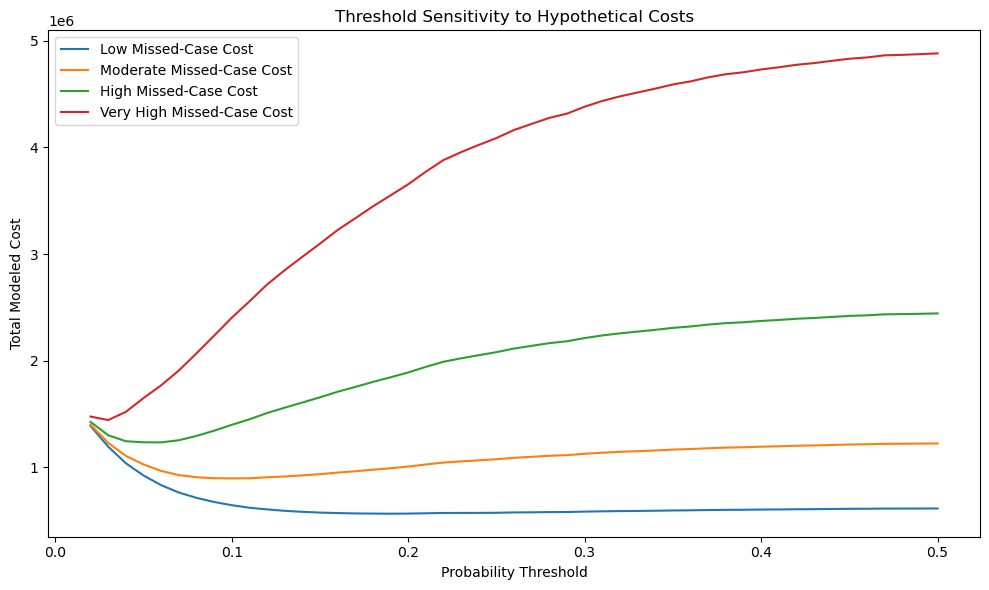

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))

for scenario_name, costs in cost_scenarios.items():

    modeled_costs = calculate_cost(
        threshold_df,
        costs["review_cost"],
        costs["missed_cost"]
    )

    ax.plot(
        threshold_df["Threshold"],
        modeled_costs,
        label=scenario_name
    )

ax.set_xlabel("Probability Threshold")
ax.set_ylabel("Total Modeled Cost")
ax.set_title("Threshold Sensitivity to Hypothetical Costs")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "day10_cost_sensitivity.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [43]:
capacity_df["Modeled_Cost"] = calculate_cost(
    capacity_df,
    REVIEW_COST,
    MISSED_CASE_COST
)

capacity_df["Cost_Per_Application"] = (
    capacity_df["Modeled_Cost"]
    / capacity_df["Applicants"]
)

display(
    capacity_df[
        [
            "Requested_Capacity",
            "Flagged",
            "TP",
            "FN",
            "Recall",
            "Modeled_Cost"
        ]
    ].round(2)
)

,Requested_Capacity,Flagged,TP,FN,Recall,Modeled_Cost
0,0.05,3076,995,3970,0.20,2061900
1,0.10,6151,1669,3296,0.34,1801775
2,0.15,9226,2176,2789,0.44,1625150
3,0.20,12301,2572,2393,0.52,1504025
4,0.25,15376,2909,2056,0.59,1412400
5,0.30,18451,3215,1750,0.65,1336275
6,0.40,24601,3697,1268,0.74,1249025
7,0.50,30751,4037,928,0.81,1232775


In [44]:
MAX_REVIEW_CAPACITY = 0.20

def flag_top_fraction(probabilities, fraction):
    probabilities = np.asarray(probabilities)

    n = len(probabilities)

    # Floor ensures review capacity is never exceeded
    k = int(np.floor(n * fraction))

    selected = np.argsort(
        -probabilities,
        kind="stable"
    )[:k]

    flagged = np.zeros(n, dtype=int)
    flagged[selected] = 1

    return flagged

best_capacity = eligible.loc[
    eligible["Modeled_Cost"].idxmin()
]

display(
    best_capacity[
        [
            "Requested_Capacity",
            "Flagged",
            "TP",
            "FN",
            "Precision",
            "Recall",
            "Modeled_Cost"
        ]
    ]
)

Requested_Capacity    1.500000e-01
Flagged               9.226000e+03
TP                    2.176000e+03
FN                    2.789000e+03
Precision             2.358552e-01
Recall                4.382679e-01
Modeled_Cost          1.625150e+06
Name: 2, dtype: float64

In [45]:
no_review_cost = int(actual.sum()) * MISSED_CASE_COST

capacity_df["Modeled_Cost_Savings_vs_No_Review"] = (
    no_review_cost - capacity_df["Modeled_Cost"]
)

print("No-review modeled cost:", no_review_cost)

display(
    capacity_df[
        [
            "Requested_Capacity",
            "Modeled_Cost",
            "Modeled_Cost_Savings_vs_No_Review"
        ]
    ].round(2)
)

No-review modeled cost: 2482500


,Requested_Capacity,Modeled_Cost,Modeled_Cost_Savings_vs_No_Review
0,0.05,2061900,420600
1,0.10,1801775,680725
2,0.15,1625150,857350
3,0.20,1504025,978475
4,0.25,1412400,1070100
5,0.30,1336275,1146225
6,0.40,1249025,1233475
7,0.50,1232775,1249725


In [46]:
threshold_df.to_csv(
    REPORT_DIR / "day10_threshold_analysis.csv",
    index=False
)

capacity_df.to_csv(
    REPORT_DIR / "day10_capacity_analysis.csv",
    index=False
)

scenario_df.to_csv(
    REPORT_DIR / "day10_cost_scenarios.csv",
    index=False
)

print("Day 10 aggregate results saved.")

Day 10 aggregate results saved.
